In [1]:
from scipy.optimize import linprog

## Creating a wrapper function
This was done for simplicity
I also copied the parameters and results from the docs

In [2]:
def simplex(c, A_ub=None, b_ub=None, A_eq=None, b_eq=None, bounds=None):
    """
    Linear programming: minimize a linear objective function subject to linear equality and inequality constraints using the tableau-based simplex method.

    Parameters
    ----------
    c : 1-D array

        The coefficients of the linear objective function to be minimized.
    A_ub
    2-D array, optional

        The inequality constraint matrix. Each row of A_ub specifies the coefficients of a linear inequality constraint on x.
    b_ub
    1-D array, optional

        The inequality constraint vector. Each element represents an upper bound on the corresponding value of A_ub @ x.
    A_eq
    2-D array, optional

        The equality constraint matrix. Each row of A_eq specifies the coefficients of a linear equality constraint on x.
    b_eq
    1-D array, optional

        The equality constraint vector. Each element of A_eq @ x must equal the corresponding element of b_eq.
    bounds
    sequence, optional

        A sequence of (min, max) pairs for each element in x, defining the minimum and maximum values of that decision variable. Use None to indicate that there is no bound. By default, bounds are (0, None) (all decision variables are non-negative). If a single tuple (min, max) is provided, then min and max will serve as bounds for all decision variables.
    callback
    callable, optional

    Callback function to be executed once per iteration.

    Returns
    -------
    resOptimizeResult

    A scipy.optimize.OptimizeResult consisting of the fields:

    x1-D array

        The values of the decision variables that minimizes the objective function while satisfying the constraints.
    funfloat

        The optimal value of the objective function c @ x.
    slack1-D array

        The (nominally positive) values of the slack variables, b_ub - A_ub @ x.
    con1-D array

        The (nominally zero) residuals of the equality constraints, b_eq - A_eq @ x.
    successbool

        True when the algorithm succeeds in finding an optimal solution.
    statusint

        An integer representing the exit status of the algorithm.

        0 : Optimization terminated successfully.

        1 : Iteration limit reached.

        2 : Problem appears to be infeasible.

        3 : Problem appears to be unbounded.

        4 : Numerical difficulties encountered.
    messagestr

        A string descriptor of the exit status of the algorithm.
    nitint

        The total number of iterations performed in all phases.


    """
    return linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='simplex')

## Testing the function
Using the example from the lecture slides

In [3]:
c = [7, 4, 6, 1]

A_eq = [[1, 2, -1, -1],
        [-1, -5, 2, 3]]
b_eq = [1, 1]

A_ub = [[-1, 0, 0, 0],
        [0, -1, 0, 0],
        [0, 0, -1, 0],
        [0, 0, 0, -1]]
b_ub = [0, 0, 0, 0]

simplex(
    c=c,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq
)

C:\Users\jackm\AppData\Local\Temp\ipykernel_21352\359376653.py:78: DeprecationWarning: `method='simplex'` is deprecated and will be removed in SciPy 1.11.0. Please use one of the HiGHS solvers (e.g. `method='highs'`) in new code.
  return linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='simplex')


 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 14.999999999999998
       x: [ 2.000e+00  0.000e+00  0.000e+00  1.000e+00]
     nit: 2

This is the same result from the lecture, so it seems to be working.

## creating a function to generate inputs

this function will generate the appropriate matricies for the simplex algorithm
based on size m and n

this function guarantees feasible solutions

some notes:
 - When I originally wrote this function, it generated a b_eq matrix of all 1's (similar to the lecture), and the c matrix contained random integers from -100 to 100
 - When m>n the system A_eq*x=b_eq with m random equations and only n unknowns is almost surely inconsistent (an overdetermined system has a solution with probability ~0 for random coefficients). And even when consistent, combined with x>=0 the feasible set was almost certainly empty.
 - to fix this, the b_eq matrix was changed to guarantee feasibility by deriving b_eq from a know point x>=0.
 - with this change, the solutions typically became unbounded for small m
 - the solution was now to make c non-negative so that the objective is bounded below by zero.

 This was tricky to get straight. Initially when I ran the benchmark, there were some results that finished very quicky (essentially all results where m>n), because the algorithm terminated early. With these changes, I was able to get consistent results.

In [9]:
import random
def create_matrix(m_rows, n_cols):
    c = [random.randint(0, 100) for _ in range(n_cols)]
    A_eq = [[random.randint(-100, 100) for _ in range(n_cols)] for _ in range(m_rows)]
    # generate a known-feasible b_eq from a random nonnegative point
    x0 = [random.uniform(0, 10) for _ in range(n_cols)]
    b_eq = [sum(a * x for a, x in zip(row, x0)) for row in A_eq]
    A_ub = [[-1 if i == j else 0 for j in range(n_cols)] for i in range(n_cols)]
    b_ub = [0 for _ in range(n_cols)]
    return c, A_eq, b_eq, A_ub, b_ub


## another worked example with the newly generated matricies

In [10]:
c, A_eq, b_eq, A_ub, b_ub = create_matrix(m_rows=2, n_cols=4)
print(c)
print(A_eq)
print(b_eq)
print(A_ub)
print(b_ub)
simplex(
    c=c,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq
)

[51, 12, 16, 60]
[[52, 64, -52, -98], [84, -43, 56, 12]]
[-116.60741211643233, 497.8062110363604]
[[-1, 0, 0, 0], [0, -1, 0, 0], [0, 0, -1, 0], [0, 0, 0, -1]]
[0, 0, 0, 0]


C:\Users\jackm\AppData\Local\Temp\ipykernel_21352\359376653.py:78: DeprecationWarning: `method='simplex'` is deprecated and will be removed in SciPy 1.11.0. Please use one of the HiGHS solvers (e.g. `method='highs'`) in new code.
  return linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='simplex')


 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 214.0173670509113
       x: [ 2.659e+00  0.000e+00  4.901e+00  0.000e+00]
     nit: 3

## use this cell to generate the benchmark data
This will take ~20+ minutes to run with the current settings

In [ ]:
max_n = 100
max_m = 30

num_trials = 30

start_m = 2
start_n = 4

file_name = "benchmark_results2.csv"

import time
import pandas as pd
df = pd.DataFrame(columns=["m", "n", "average_time", "average_num_pivots"])
for n in range(start_n, max_n + 1, 1):
    for m in range(start_m, max_m + 1, 1):
        total_time = 0
        num_pivots = 0
        t = 0
        while t < num_trials:
            c, A_eq, b_eq, A_ub, b_ub = create_matrix(m_rows=m, n_cols=n)
            start_time = time.process_time()
            result = simplex(
                c=c,
                A_ub=A_ub,
                b_ub=b_ub,
                A_eq=A_eq,
                b_eq=b_eq
            )
            #check if successful
            success = result.success
            if success:
                t+=1
                end_time = time.process_time()
                total_time += end_time - start_time
                num_pivots += result.nit
        average_num_pivots = num_pivots / num_trials
        average_time = total_time / num_trials
        print(f"Average time for m={m}, n={n} over {num_trials} trials: {average_time} seconds")
        print(f"Average number of pivots for m={m}, n={n} over {num_trials} trials: {average_num_pivots}")
        df = pd.concat([df, pd.DataFrame([{"m": m, "n": n, "average_time": average_time, "average_num_pivots": average_num_pivots}])], ignore_index=True)
            
df.to_csv(file_name, index=False)

Average time for m=2, n=4 over 30 trials: 0.004166666666666667 seconds
Average number of pivots for m=2, n=4 over 30 trials: 2.3333333333333335


C:\Users\jackm\AppData\Local\Temp\ipykernel_21352\359376653.py:78: DeprecationWarning: `method='simplex'` is deprecated and will be removed in SciPy 1.11.0. Please use one of the HiGHS solvers (e.g. `method='highs'`) in new code.
  return linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='simplex')
C:\Users\jackm\AppData\Local\Temp\ipykernel_21352\101128326.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([{"m": m, "n": n, "average_time": average_time, "average_num_pivots": average_num_pivots}])], ignore_index=True)


Average time for m=3, n=4 over 30 trials: 0.0026041666666666665 seconds
Average number of pivots for m=3, n=4 over 30 trials: 3.2
Average time for m=4, n=4 over 30 trials: 0.0020833333333333333 seconds
Average number of pivots for m=4, n=4 over 30 trials: 4.1
Average time for m=5, n=4 over 30 trials: 0.0036458333333333334 seconds
Average number of pivots for m=5, n=4 over 30 trials: 4.033333333333333


C:\Users\jackm\AppData\Local\Temp\ipykernel_21352\359376653.py:78: OptimizeWarning: A_eq does not appear to be of full row rank. To improve performance, check the problem formulation for redundant equality constraints.
  return linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='simplex')


Average time for m=6, n=4 over 30 trials: 0.004166666666666667 seconds
Average number of pivots for m=6, n=4 over 30 trials: 4.033333333333333
Average time for m=7, n=4 over 30 trials: 0.004166666666666667 seconds
Average number of pivots for m=7, n=4 over 30 trials: 4.0
Average time for m=8, n=4 over 30 trials: 0.00625 seconds
Average number of pivots for m=8, n=4 over 30 trials: 4.0
Average time for m=9, n=4 over 30 trials: 0.0078125 seconds
Average number of pivots for m=9, n=4 over 30 trials: 4.033333333333333
Average time for m=10, n=4 over 30 trials: 0.0046875 seconds
Average number of pivots for m=10, n=4 over 30 trials: 4.0
Average time for m=11, n=4 over 30 trials: 0.004166666666666667 seconds
Average number of pivots for m=11, n=4 over 30 trials: 4.033333333333333
Average time for m=12, n=4 over 30 trials: 0.0046875 seconds
Average number of pivots for m=12, n=4 over 30 trials: 4.0
Average time for m=13, n=4 over 30 trials: 0.0046875 seconds
Average number of pivots for m=13,

## visualizing the data
change the csv names to whatever results you want to check.
you dont need to run the previous cell if you already have the data.

the first few graphs show the duration (processor time)
the last few graph are exactly the same except they show number of pivots

I think we should add another graph showing time vs number of pivots (I expect it to be completely linear)

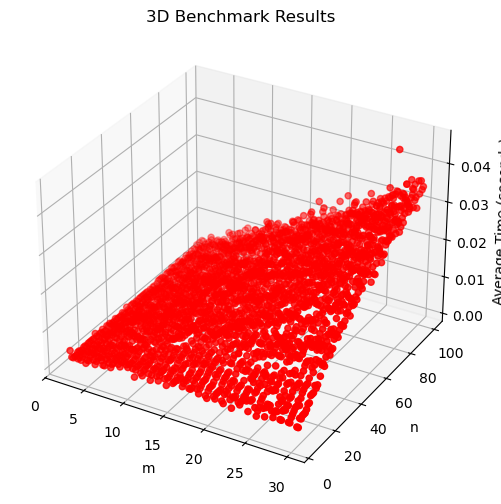

In [12]:
df = pd.read_csv("benchmark_results2.csv")
df.head()

import matplotlib.pyplot as plt

#show a 3d plot
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df["m"], df["n"], df["average_time"], c='r', marker='o')
ax.set_xlabel("m")
ax.set_ylabel("n")
ax.set_zlabel("Average Time (seconds)")
ax.set_title("3D Benchmark Results")
plt.show()

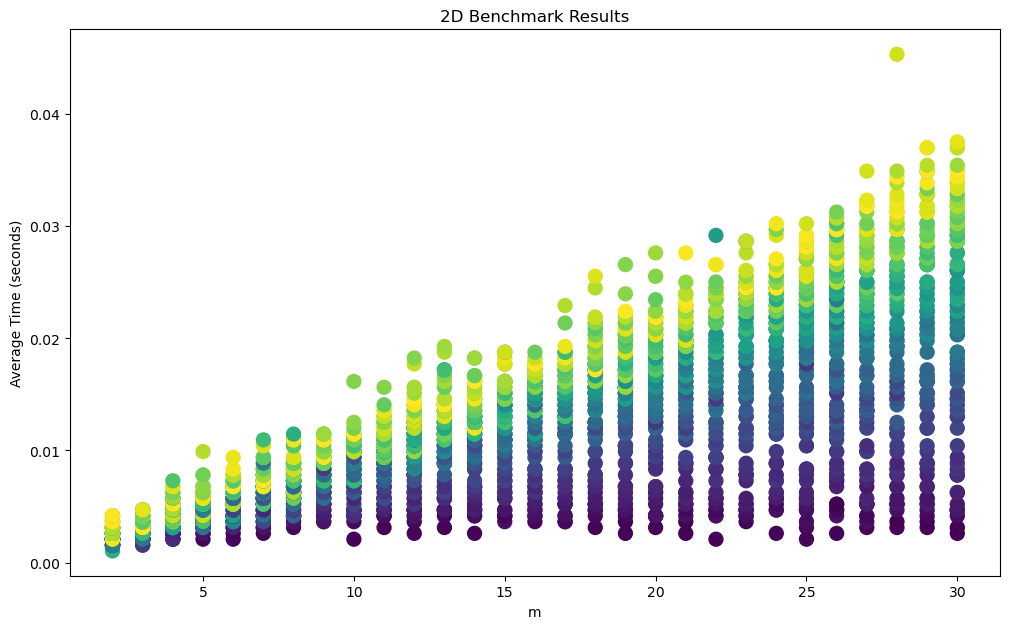

In [13]:
df = pd.read_csv("benchmark_results2.csv")

import matplotlib.pyplot as plt


plt.figure(figsize=(10, 6))
n_values = sorted(df["n"].unique())
color_map = {n: plt.cm.viridis(i / (len(n_values) - 1)) for i, n in enumerate(n_values)}

for m, group in df.groupby("m"):
    group = group.sort_values("average_time")          # largest time drawn last → on top
    plt.scatter(
        group["m"],
        group["average_time"],
        c=[color_map[n] for n in group["n"]],          # manual per-point colors
        s=100,
    )

from matplotlib.lines import Line2D

handles = [
    Line2D([], [], marker="o", linestyle="", color=color_map[n], label=f"n={n}")
    for n in n_values
]
#plt.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=2)
plt.tight_layout()
plt.xlabel("m")
plt.ylabel("Average Time (seconds)")
plt.title("2D Benchmark Results")

plt.show()

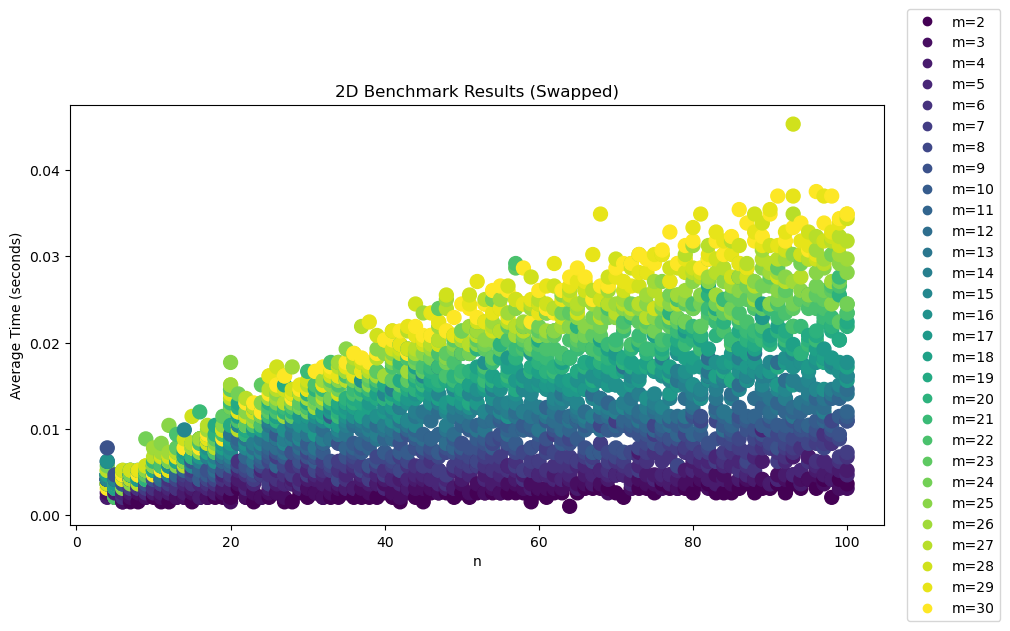

In [14]:
plt.figure(figsize=(10, 6))
n_values = sorted(df["m"].unique())
color_map = {n: plt.cm.viridis(i / (len(n_values) - 1)) for i, n in enumerate(n_values)}

for n, group in df.groupby("n"):
    group = group.sort_values("average_time")          # largest time drawn last → on top
    plt.scatter(
        group["n"],
        group["average_time"],
        c=[color_map[m] for m in group["m"]],          # manual per-point colors
        s=100,
    )

handles = [
    Line2D([], [], marker="o", linestyle="", color=color_map[m], label=f"m={m}")
    for m in n_values
]
plt.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1)
plt.tight_layout()
plt.xlabel("n")
plt.ylabel("Average Time (seconds)")
plt.title("2D Benchmark Results (Swapped)")

plt.show()

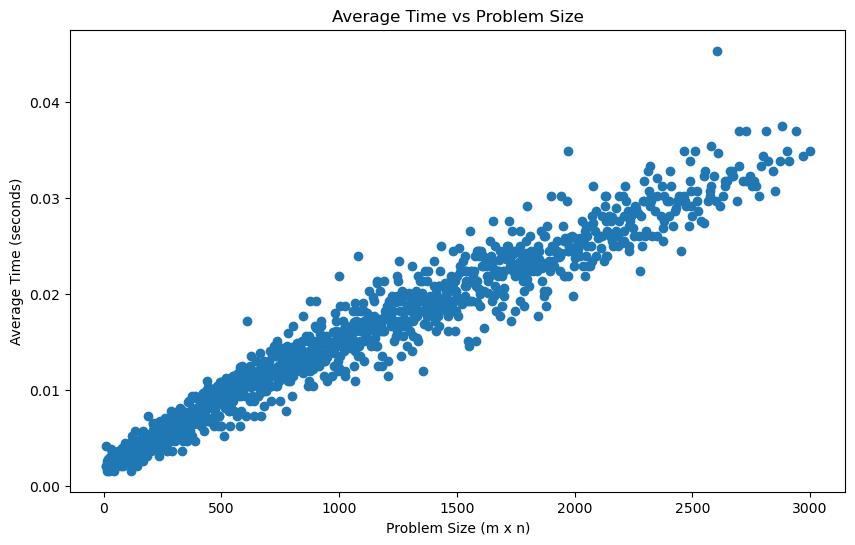

In [17]:
# plot average times for vs mxn (size of problem)
df=pd.read_csv("benchmark_results2.csv")
plt.figure(figsize=(10, 6))

average_times = dict()

for r in df.itertuples():
    size = r.m * r.n
    time = r.average_time
    if size not in average_times:
        average_times[size] = []
    average_times[size].append(time)

# compute the average for each size
average_times = {size: sum(times) / len(times) for size, times in average_times.items()}

# plot the results
sizes = sorted(average_times.keys())
times = [average_times[size] for size in sizes]
plt.scatter(sizes, times)
plt.xlabel("Problem Size (m x n)")
plt.ylabel("Average Time (seconds)")
plt.title("Average Time vs Problem Size")

df=pd.read_csv("benchmark_results.csv")
# add this data to the plot in the same way, but with a different color
average_times_new = dict()
for r in df.itertuples():
    size = r.m * r.n
    time = r.average_time
    if size not in average_times_new:
        average_times_new[size] = []
    average_times_new[size].append(time)

plt.show()

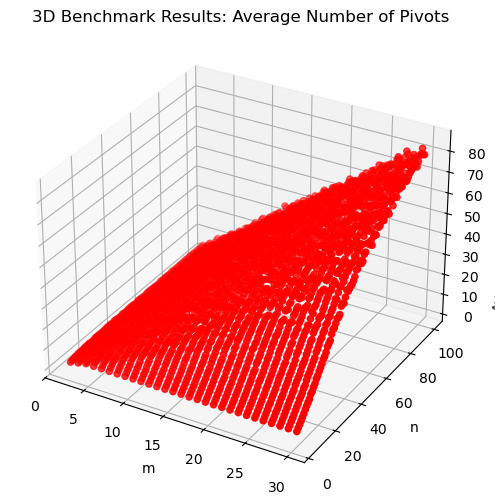

In [18]:
df = pd.read_csv("benchmark_results2.csv")
df.head()

import matplotlib.pyplot as plt

#show a 3d plot
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df["m"], df["n"], df["average_num_pivots"], c='r', marker='o')
ax.set_xlabel("m")
ax.set_ylabel("n")
ax.set_zlabel("Average Number of Pivots")
ax.set_title("3D Benchmark Results: Average Number of Pivots")
plt.show()

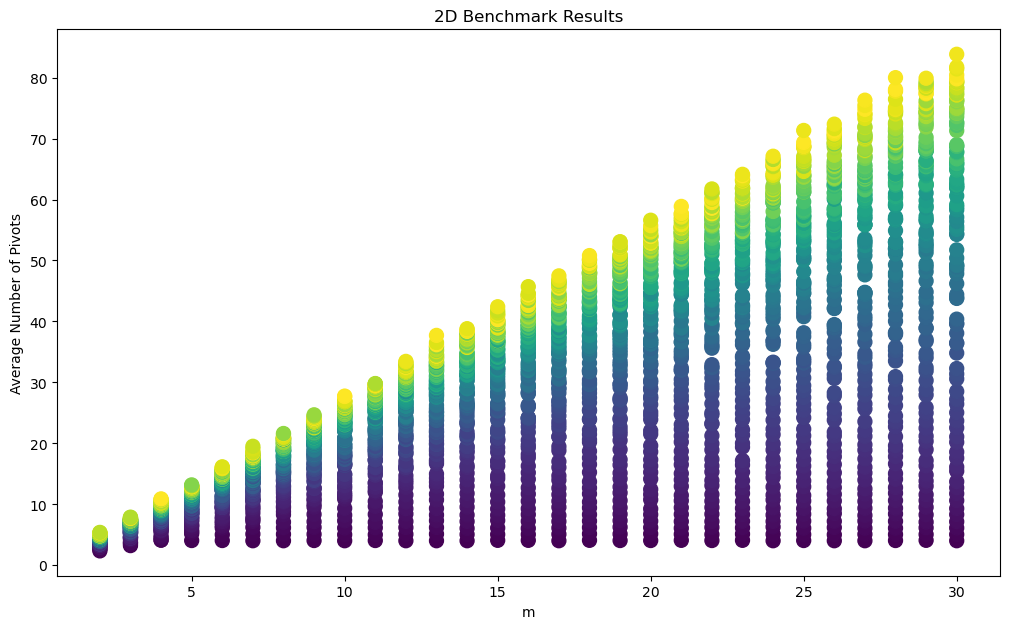

In [19]:
df = pd.read_csv("benchmark_results2.csv")

import matplotlib.pyplot as plt


plt.figure(figsize=(10, 6))
n_values = sorted(df["n"].unique())
color_map = {n: plt.cm.viridis(i / (len(n_values) - 1)) for i, n in enumerate(n_values)}

for m, group in df.groupby("m"):
    group = group.sort_values("average_num_pivots")          # largest time drawn last → on top
    plt.scatter(
        group["m"],
        group["average_num_pivots"],
        c=[color_map[n] for n in group["n"]],          # manual per-point colors
        s=100,
    )

from matplotlib.lines import Line2D

handles = [
    Line2D([], [], marker="o", linestyle="", color=color_map[n], label=f"n={n}")
    for n in n_values
]
#plt.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=2)
plt.tight_layout()
plt.xlabel("m")
plt.ylabel("Average Number of Pivots")
plt.title("2D Benchmark Results")

plt.show()

In [ ]:
plt.figure(figsize=(10, 6))
n_values = sorted(df["m"].unique())
color_map = {n: plt.cm.viridis(i / (len(n_values) - 1)) for i, n in enumerate(n_values)}

for n, group in df.groupby("n"):
    group = group.sort_values("average_num_pivots")          # largest time drawn last → on top
    plt.scatter(
        group["n"],
        group["average_num_pivots"],
        c=[color_map[m] for m in group["m"]],          # manual per-point colors
        s=100,
    )

handles = [
    Line2D([], [], marker="o", linestyle="", color=color_map[m], label=f"m={m}")
    for m in n_values
]
plt.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1)
plt.tight_layout()
plt.xlabel("n")
plt.ylabel("Average Number of Pivots")
plt.title("2D Benchmark Results (Swapped)")

plt.show()